# Adaptive Optics Simulation — Part I using **AOtools**

## What is AOtools ?
- collection of tools, equations and functions for Adaptive Optics, in Python.
- Full documentation can be found at [read-the-docs](https://aotools.readthedocs.io/en/latest/).
- Full AOtools package can be found [here](https://github.com/aotools/aotools/)
- A set of notebooks illustrating the functionalities of **AOtools** can be found [here](https://github.com/aotools/aotools_tests/)

## Getting started
To run and work with this notebook, you need a Python environment, which inclues:
- aotools
- jupyter

We recommend a dedicated conda environment (install [Miniconda](https://www.anaconda.com/download) if you don't have it):

    conda create -n aosim python=3.11
    conda activate aosim
    pip install aotools matplotlib jupyter astropy

Then launch the notebook:

    jupyter notebook


## Objectives & plan
- **Image formation** basics: propagate from pupil to focal plane and measuring a PSF (first zero, encircled energy, FWHM)
- **Optical aberrations**: Zernike modes, wavefront error, Strehl ratio
- **Atmospheric turbulence**: $r_0$, seeing and $C_n^2$, with the $\lambda^{6/5}$ scaling, and estimate $\tau_0$ / $\theta_0$.
- **Generate phase screens**: Kolmogorov vs von Kármán, validation (structure function and power spectrum), evolving phase screens
- **Imaging through turbulence**: instantaneous & long-exposure PSFs, etc.

Today we will use:

| Functionality | `aotools` entry points |
|---|---|
| Fourier optics | `ft2`, `ift2` |
| Pupils & images | `circle`, `azimuthal_average`, `encircled_energy` |
| Aberrations | `zernikeArray`, `zernike_noll`, `zernike_nm`, `phaseFromZernikes`, `zernIndex` |
| Turbulence parameters | `r0_to_seeing`, `seeing_to_r0`, `r0_to_cn2`, `cn2_to_r0`, `coherenceTime`, `isoplanaticAngle`, `rytov_variance` |
| Phase screens | `turbulence.phasescreen.ft_phase_screen`, `ft_sh_phase_screen`, `structure_function_kolmogorov`, `structure_function_vk` |

### Reminders and Conventions

- Phase screens from `aotools` are in **radians of phase**: $\mathrm{OPD\,[m]} = \phi\,[\mathrm{rad}] \times \lambda / 2\pi$.
- $r_0$ is quoted at $\lambda = 500$ nm unless stated otherwise, and scales as $r_0 \propto \lambda^{6/5}$.
- radian to arcseconds = 206264.8 -- arcseconds to radian: 4.848e-6

In [14]:
# ============================================================
# Setup — run this cell first
# ============================================================
# if %matplotlib widget doesn't work, try %matplotlib inline instead
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm

import aotools
from aotools.turbulence import (phasescreen, infinitephasescreen,
                                temporal_ps, slopecovariance, profile_compression)

import scipy.signal

from astropy.visualization import imshow_norm, LogStretch, SqrtStretch, AsinhStretch, PercentileInterval


# Wavelength used throughout the notebook (r0 values are quoted at this wavelength)
WAVELENGTH = 500e-9  # [m]

## 1. Image formation
**Fourier optics, diffraction & image formation (~20min)**

Light propagation between conjugate planes is a **Fourier transform**. 
For a pupil sampled on $N$ pixels of size $\delta_x$ [m], `aotools.ft2` returns the focal-plane *field* with the correct physical scaling; the focal-plane pixel size is $1/(N\,\delta_x)$ [1/m]. 
The focal-plane pixel size in arcseconds is thus $\lambda/(N\,\delta_x) \times 206264.8 $ [arcsec/px] 

To avoid aliasing artifact, we need to increase the resolution and pad the pupil plane array with zeros.

See also [this book](https://www.spiedigitallibrary.org/ebooks/PM/Numerical-Simulation-of-Optical-Wave-Propagation-with-Examples-in-MATLAB/eISBN-9780819483270/10.1117/3.866274).

We will:
1. check the scaled FFT round-trip and the pixel scales;
2. compute the diffraction-limited PSF of a circular aperture (the **Airy pattern**);
3. measure it: first zero, encircled energy, FWHM, and the MTF cut-off at $D/\lambda$.

### 1.1 First look to aotools fourier transform

ft2/ift2 round-trip max error: 4.440892098500626e-16
Pupil pixel scale        : 0.0156 m/pxl
Fourier pixel scale      : 1.00 1/m
focal-plane angular pixel scale: 0.103 arcsec/pxl  (= lambda/(N*delta_x))


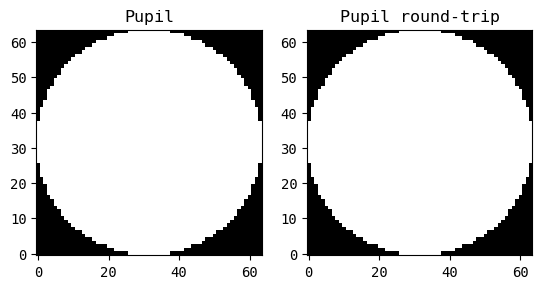

In [9]:
# --- 1.1 Scaled Fourier transforms --------------------------------------
N = 64           # pixels
D=1.0          # m (aperture diameter)
delta_x = D/64   # m per pixel (a 1 m aperture sampled on 64 pixels)

pupil = aotools.circle(N/2, N)          # centred disk, radius N/2 px

# Forward transform (pupil -> focal-plane field) and back
E_focal    = aotools.ft2(pupil, delta=delta_x)
pupil_back = aotools.ift2(E_focal, delta_f=1/(N*delta_x)).real

print('ft2/ift2 round-trip max error:', np.abs(pupil_back - pupil).max())

delta_f = 1/(N*delta_x)
print(f'Pupil pixel scale        : {delta_x:.4f} m/pxl')
print(f'Fourier pixel scale      : {delta_f:.2f} 1/m')
print(f'focal-plane angular pixel scale: {WAVELENGTH*delta_f*206265:.3f} arcsec/pxl  (= lambda/(N*delta_x))')


plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(pupil, cmap='gray')
plt.title('Pupil')
plt.subplot(1, 2, 2)
plt.imshow(pupil_back, cmap='gray')
plt.title('Pupil round-trip')
plt.show()

## From pupil to PSF: the Airy pattern

The focal-plane **intensity** PSF is $|\mathcal{F}\{P\}|^2$. 

For a circular pupil of diameter $D$ this is the Airy pattern: a central peak of full width $\approx 1.03\,\lambda/D$ (FWHM), a first zero at $1.22\,\lambda/D$, and $\approx 84\%$ of the light within the first dark ring.

Zero-padding the pupil by a factor `pad_factor` samples the PSF `pad_factor`× finer — a minimum of a factor 2 is necessary to avoid aliasing/artifact (Nyquist-Shannon sampling theorem).

focal-plane pixel scale: 6.45 mas/pxl
diffraction limit lambda/D = 103.1 mas


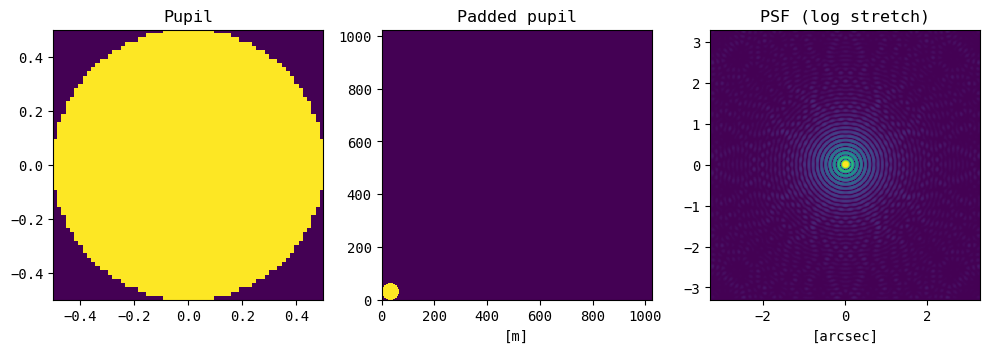

In [47]:
# --- 1.2 Diffraction-limited PSF of a circular aperture -----------------
N   = 64              # pupil pixels across the array
D   = 1.0              # telescope diameter [m]
delta_x = D / N        # m/pxl
pad_factor = 16                # zero-padding factor -> oversampled PSF

pupil = aotools.circle(D/delta_x/2, N)

# Place the pupil in a larger (padded) array -> finer sampling in the focal plane
padded_pupil = np.zeros((N*pad_factor, N*pad_factor))
padded_pupil[:N, :N] = pupil

# E-field in the pupil plane
wavefront = padded_pupil * np.exp(1j*0)  # flat wavefront; the np.exp is not necessary, but included for clarity
# E-field in the focal plane
E_focal = aotools.ft2(wavefront, delta=delta_x)
# Pupil -> focal plane
psf = np.abs(E_focal)**2

# Focal-plane scales
fpxl_rad    = WAVELENGTH / (N*pad_factor*delta_x)     # rad per focal-plane pixel
fpxl_arcsec = fpxl_rad * 206265                # arcsec per focal-plane pixel
print(f'focal-plane pixel scale: {fpxl_arcsec*1000:.2f} mas/pxl')
print(f'diffraction limit lambda/D = {WAVELENGTH/D*206265*1000:.1f} mas')

fig, ax = plt.subplots(1, 3, figsize=(10, 4.5))


im0 = ax[0].imshow(pupil, extent=[-D/2, D/2, -D/2, D/2])
ax[0].set_title('Pupil'); ax[1].set_xlabel('[m]')

im0 = ax[1].imshow(padded_pupil)
ax[1].set_title('Padded pupil')
ax[1].set_xlabel('[m]')

ext = N*pad_factor/2 * fpxl_arcsec
im1 = imshow_norm(psf, stretch=LogStretch(a=1e4), interval=PercentileInterval(99.95),
                  ax=ax[2], extent=[-ext, ext, -ext, ext])
ax[2].set_title('PSF (log stretch)'); ax[2].set_xlabel('[arcsec]')
plt.tight_layout()

## 1.3 Measuring a PSF
**First zero, EE50, FWHM**

Because the Airy pattern is circularly symmetric, `aotools.azimuthal_average` reduces it to a 1-D profile. From it we measure the **first zero** and the **encircled energy** (`aotools.encircled_energy`), then the **FWHM** and the **MTF** — the modulus of the FT of the PSF — which cuts off at $D/\lambda$ cycles per radian: no spatial frequency beyond the telescope aperture gets through.

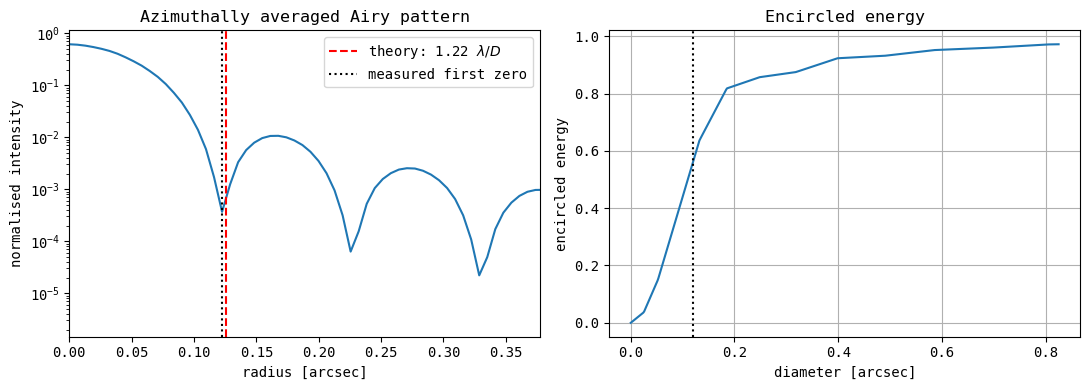

first Airy zero : measured 0.122 arcsec | theory 0.126 arcsec
EE50 diameter   : 0.121 arcsec = 1.17 lambda/D (Airy: ~1.1)


In [48]:
# --- 1.3 Measuring the Airy pattern -------------------------------------
# The PSF is circularly symmetric -> azimuthal average (aotools.azimuthal_average)
cc = psf.shape[0]//2
box=128
azi = aotools.azimuthal_average(psf[cc-box:cc+box, cc-box:cc+box])
r_arcsec = np.arange(len(azi)) * fpxl_arcsec


# First zero of the Airy pattern: theory 1.22 lambda/D
first_zero = 1.22 * WAVELENGTH / D * 206265   # arcsec
# locate the measured first zero: the first LOCAL minimum of the profile
# (searching a window for the global min would jump to the 2nd/3rd zero)
i_th = np.argmin(np.abs(r_arcsec - first_zero))
i_zero = int(np.argmax(np.diff(azi[:i_th+8]) > 0))   # first index where the profile rises again

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(r_arcsec, azi)
ax[0].axvline(first_zero, color='r', ls='--', label='theory: 1.22 $\\lambda/D$')
ax[0].axvline(r_arcsec[i_zero], color='k', ls=':', label='measured first zero')
ax[0].set_xlabel('radius [arcsec]'); ax[0].set_ylabel('normalised intensity')
ax[0].semilogy()
ax[0].set_title('Azimuthally averaged Airy pattern')
ax[0].legend(); ax[0].set_xlim(0, 3*first_zero)

# Encircled energy curve (aotools.encircled_energy)
box=128
diam, ee = aotools.encircled_energy(psf[cc-box:cc+box, cc-box:cc+box], eeDiameter=False)
ee50 = aotools.encircled_energy(psf, fraction=0.5)

ax[1].plot(diam*fpxl_arcsec, ee)
ax[1].axvline(ee50*fpxl_arcsec, color='k', ls=':', label='EE50 diameter')
ax[1].set_xlabel('diameter [arcsec]'); ax[1].set_ylabel('encircled energy')
ax[1].set_title('Encircled energy'); ax[1].grid(True)
plt.tight_layout()
plt.show()

print(f'first Airy zero : measured {r_arcsec[i_zero]:.3f} arcsec | theory {first_zero:.3f} arcsec')
print(f'EE50 diameter   : {ee50*fpxl_arcsec:.3f} arcsec = {ee50*fpxl_rad/WAVELENGTH*D:.2f} lambda/D (Airy: ~1.1)')


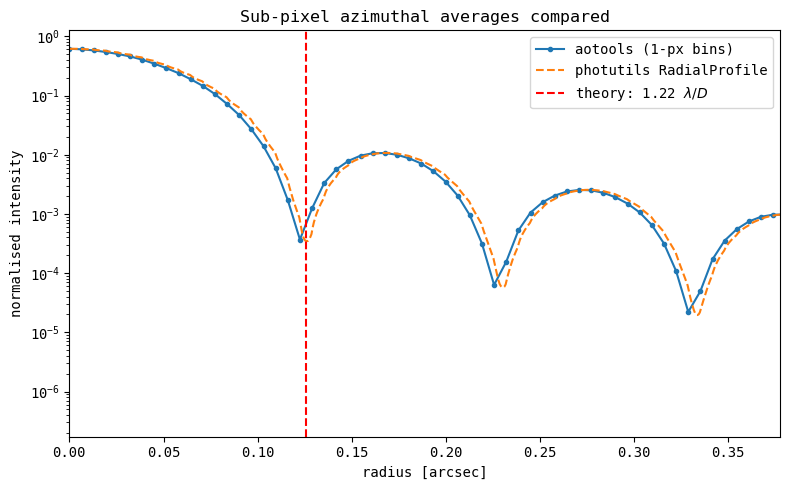

In [ ]:
# --- Sub-pixel azimuthal average with photutils ----------------------------
# photutils.profiles.RadialProfile uses fractional-pixel-weighted annuli,
# which gives a true sub-pixel azimuthal average (each pixel contributes
# to annuli proportionally to its fractional overlap).

from photutils.profiles import RadialProfile

# RadialProfile expects the center in (x, y) pixel coordinates
data = psf[cc-box:cc+box, cc-box:cc+box]
nx, ny = data.shape
r_px = np.sqrt((np.arange(nx) - (nx-1)/2)**2 + (np.arange(ny) - (ny-1)/2)**2)
center_xy = ((nx-1)/2, (ny-1)/2)   # (x, y) of the PSF peak in the cutout
bin_width = 0.1   # pixels
r_max = r_px.max()
bins = np.arange(0, r_max + bin_width, bin_width)

rp = RadialProfile(data, center_xy, radii=bins, error=None)
azi_phot = rp.profile
r_phot_arcsec = rp.radius * fpxl_arcsec   # radius [pixels] -> [arcsec]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(r_arcsec, azi, 'o-', ms=3, label='aotools (1-px bins)')
ax.plot(r_phot_arcsec, azi_phot, '--', lw=1.5, label='photutils RadialProfile')
ax.axvline(first_zero, color='r', ls='--', label='theory: 1.22 $\\lambda/D$')
ax.set_xlabel('radius [arcsec]'); ax.set_ylabel('normalised intensity')
ax.semilogy()
ax.set_title('Sub-pixel azimuthal averages compared')
ax.legend(); ax.set_xlim(0, 3*first_zero)
plt.tight_layout()
plt.show()

FWHM = 0.103 arcsec = 1.00 lambda/D  (Airy: 1.03)


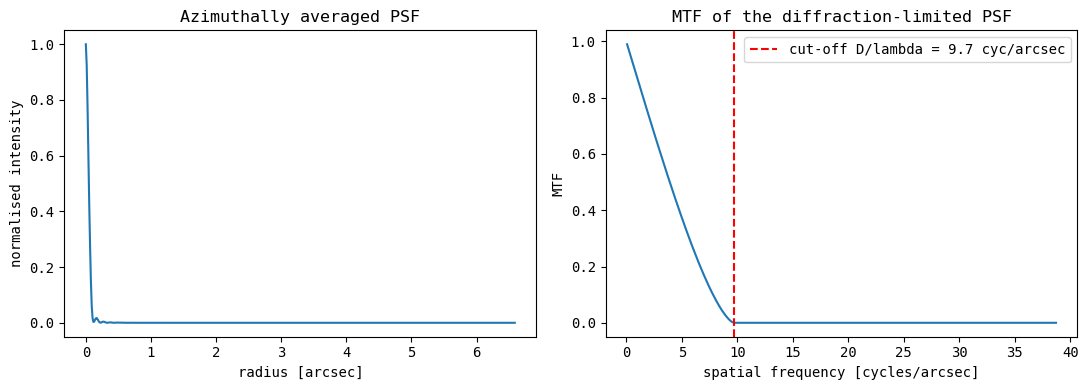

In [ ]:
# # --- 1.4 PSF metrics: FWHM, encircled energy, MTF ------------------------
# N = 128; D = 1.0; delta_x = D/N; PAD = 8
# pupil = aotools.circle(N/2, N)
# padded = np.zeros((N*PAD, N*PAD), dtype=complex); padded[:N, :N] = pupil
# psf = np.abs(aotools.ft2(padded, delta=delta_x))**2
# psf /= psf.sum()                       # unit total flux
# fpxl_rad = WAVELENGTH/(N*PAD*delta_x)  # rad per focal-plane pixel

# # FWHM from the azimuthal average
# azi = aotools.azimuthal_average(psf)
# half = np.where(azi < azi.max()/2)[0]
# fwhm_px = 2*half[0]
# print(f'FWHM = {fwhm_px*fpxl_rad*206265:.3f} arcsec = {fwhm_px*fpxl_rad/WAVELENGTH*D:.2f} lambda/D  (Airy: 1.03)')

# # MTF = |FT(PSF)|; its frequency axis is 1/(N_pad * fpxl_rad) cycles/rad per pixel
# n_pad = N*PAD
# mtf = np.abs(np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(psf))))
# freq_px = 1/(n_pad*fpxl_rad)                              # cycles/rad per pixel
# f_axis = (np.arange(n_pad) - n_pad/2) * freq_px / 206265  # cycles/arcsec
# mtf_row = mtf[n_pad//2, n_pad//2:] / mtf[n_pad//2, n_pad//2]  # positive-freq half
# f_pos = f_axis[n_pad//2:]                                     # matching half axis
# cutoff = D/WAVELENGTH/206265                              # cycles/arcsec

# fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# ax[0].plot(np.arange(len(azi))*fpxl_rad*206265, azi/azi.max())
# ax[0].set_xlabel('radius [arcsec]'); ax[0].set_ylabel('normalised intensity')
# ax[0].set_title('Azimuthally averaged PSF')
# ax[1].plot(f_pos[f_pos > 0], mtf_row[f_pos > 0])
# ax[1].axvline(cutoff, color='r', ls='--', label=f'cut-off D/lambda = {cutoff:.1f} cyc/arcsec')
# ax[1].set_xlabel('spatial frequency [cycles/arcsec]'); ax[1].set_ylabel('MTF')
# ax[1].set_title('MTF of the diffraction-limited PSF'); ax[1].legend()
# plt.tight_layout()